# BOOK MARKET ANALYTICS – BOOKS TO SCRAPE

**Module:** Data Science 500

## 1. Introduction

This project focuses on analysing book market data collected from the Books to Scrape website. The aim is to investigate factors that influence book prices and ratings by collecting, cleaning and analysing publicly available book information.

BeautifulSoup will be used to scrape the website, while Python libraries such as Pandas, NumPy, Matplotlib and Seaborn will support data processing and visualisation.

A Linear Regression model will be developed to predict book prices using relevant features extracted from the dataset.

## 2. Project Objectives

- Collect book information from the Books to Scrape website.
- Clean and prepare the collected dataset.
- Analyse book prices, ratings and genre patterns.
- Create visualisations to communicate findings.
- Develop a Linear Regression model to predict book prices.
- Evaluate the model and provide recommendations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import time
import re

print("Books to Scrape Assignment - Environment Ready!")

Books to Scrape Assignment - Environment Ready!


## 3. Web Scraping and Data Acquisition

### 3.1 Connecting to the Website

The Books to Scrape website is used as the data source for this project. Python's Requests library is used to retrieve the website's HTML content, while BeautifulSoup is used to extract the required information from the web pages.

In [2]:
# Website URL
base_url = "https://books.toscrape.com/"

# Send a request to the website
response = requests.get(base_url, timeout=30)

# Check whether the connection was successful
print("Website Status Code:", response.status_code)

# Extract HTML content
soup = BeautifulSoup(response.text, "html.parser")

# Display website title
print("Website Title:", soup.title.text.strip())

Website Status Code: 200
Website Title: All products | Books to Scrape - Sandbox


### 3.2 Extracting Book Information

BeautifulSoup is used to locate individual book listings and extract their titles, prices, star ratings and stock availability. This initial extraction tests the data collection process before applying it to the complete catalogue.

In [5]:
# Select the first book
first_book = soup.select_one("article.product_pod")

# Extract book details
title = first_book.h3.a["title"]
price = first_book.select_one(".price_color").get_text(strip=True)
rating = first_book.select_one(".star-rating")["class"][1]

# Convert price into a numeric value
price = float(price.replace("£", "").replace("Â", ""))

# Extract stock status from catalogue
availability = first_book.select_one(".availability").get_text(" ", strip=True)

# Get individual book page
book_link = first_book.h3.a["href"]
book_url = requests.compat.urljoin(base_url, book_link)

# Visit individual book page
book_response = requests.get(book_url, timeout=30)
book_response.encoding = book_response.apparent_encoding

book_soup = BeautifulSoup(book_response.text, "html.parser")

# Extract detailed stock information
detail_availability = book_soup.select_one(".product_main .availability")
detail_text = detail_availability.get_text(" ", strip=True)

# Extract quantity if available
quantity_match = re.search(r"\((\d+)\s+available\)", detail_text)
quantity = int(quantity_match.group(1)) if quantity_match else None

# Display results
print("BOOK INFORMATION")
print("-------------------------")
print("Title:", title)
print("Price: £", price)
print("Rating:", rating)
print("Availability:", availability)
print("Detailed Stock:", detail_text)
print("Quantity:", quantity)

BOOK INFORMATION
-------------------------
Title: A Light in the Attic
Price: £ 51.77
Rating: Three
Availability: In stock
Detailed Stock: In stock (22 available)
Quantity: 22


### 3.3 Collecting the Complete Book Catalogue

The scraper navigates through the different book categories and their pagination pages to collect the available catalogue information. It also visits individual book pages to retrieve detailed stock quantities. This process creates a comprehensive dataset for further analysis.

In [6]:
# Create a reusable website session
session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0 (compatible; BookMarketAnalytics/1.0)"
})

# Function to retrieve and parse a webpage
def get_soup(url):
    response = session.get(url, timeout=30)
    response.raise_for_status()
    response.encoding = response.apparent_encoding
    return BeautifulSoup(response.text, "html.parser")


# Get all book categories
home_soup = get_soup(base_url)

category_links = home_soup.select(
    "div.side_categories ul li ul li a"
)

print("Categories found:", len(category_links))


# Store all collected books
books_data = []
seen_books = set()


# Visit each category
for category_link in category_links:

    category = category_link.get_text(strip=True)
    category_url = requests.compat.urljoin(
        base_url, category_link["href"]
    )

    print("Collecting category:", category)

    current_url = category_url

    # Navigate through category pages
    while current_url:

        page_soup = get_soup(current_url)

        book_cards = page_soup.select("article.product_pod")

        for book in book_cards:

            title = book.h3.a["title"]

            book_url = requests.compat.urljoin(
                current_url, book.h3.a["href"]
            )

            # Avoid duplicate books
            if book_url in seen_books:
                continue

            seen_books.add(book_url)

            price_text = book.select_one(
                ".price_color"
            ).get_text(strip=True)

            price = float(
                price_text.replace("£", "").replace("Â", "")
            )

            rating = book.select_one(
                ".star-rating"
            )["class"][1]

            availability = book.select_one(
                ".availability"
            ).get_text(" ", strip=True)

            stock_status = (
                "In stock" if "In stock" in availability
                else "Out of stock"
            )

            # Visit individual book page for exact quantity
            detail_soup = get_soup(book_url)

            detail_availability = detail_soup.select_one(
                ".product_main .availability"
            )

            detail_text = detail_availability.get_text(
                " ", strip=True
            )

            quantity_match = re.search(
                r"\((\d+)\s+available\)", detail_text
            )

            quantity = (
                int(quantity_match.group(1))
                if quantity_match else None
            )

            # Save book information
            books_data.append({
                "Title": title,
                "Price_GBP": price,
                "Rating": rating,
                "Availability": stock_status,
                "Quantity": quantity,
                "Category": category
            })

            time.sleep(0.5)

        # Find the next page
        next_page = page_soup.select_one("li.next a")

        if next_page:
            current_url = requests.compat.urljoin(
                current_url, next_page["href"]
            )
        else:
            current_url = None

    print("Books collected so far:", len(books_data))


# Convert collected information into a DataFrame
books_df = pd.DataFrame(books_data)

print("\nSCRAPING COMPLETED")
print("-------------------------")
print("Total books collected:", len(books_df))
print("Total categories:", books_df["Category"].nunique())

# Display first five records
display(books_df.head())

Categories found: 50
Books collected so far: 11
Books collected so far: 43
Books collected so far: 69
Books collected so far: 144
Books collected so far: 163
Books collected so far: 174
Books collected so far: 209
Books collected so far: 226
Books collected so far: 291
Books collected so far: 320
Books collected so far: 327
Books collected so far: 437
Books collected so far: 450
Books collected so far: 602
Books collected so far: 618
Books collected so far: 623
Books collected so far: 690
Books collected so far: 738
Books collected so far: 744
Books collected so far: 798
Books collected so far: 812
Books collected so far: 831
Books collected so far: 832
Books collected so far: 840
Books collected so far: 847
Books collected so far: 856
Books collected so far: 857
Books collected so far: 858
Books collected so far: 868
Books collected so far: 885
Books collected so far: 903
Books collected so far: 933
Books collected so far: 939
Books collected so far: 951
Books collected so far: 956
Bo

,Title,Price_GBP,Rating,Availability,Quantity,Category
0,It's Only the Himalayas,45.17,Two,In stock,19,Travel
1,Full Moon over Noah’s Ark: An Odyssey to Mount...,49.43,Four,In stock,15,Travel
2,See America: A Celebration of Our National Par...,48.87,Three,In stock,14,Travel
3,Vagabonding: An Uncommon Guide to the Art of L...,36.94,Two,In stock,8,Travel
4,Under the Tuscan Sun,37.33,Three,In stock,7,Travel


In [7]:
# Check the final scraping results

print("SCRAPING RESULTS")
print("========================")
print("Total books:", len(books_df))
print("Total categories:", books_df["Category"].nunique())

print("\nFirst 10 books:")
display(books_df.head(10))

print("\nLast 5 books:")
display(books_df.tail())

print("\nBooks collected per category:")
display(
    books_df["Category"].value_counts()
)

SCRAPING RESULTS
Total books: 1000
Total categories: 50

First 10 books:


,Title,Price_GBP,Rating,Availability,Quantity,Category
0,It's Only the Himalayas,45.17,Two,In stock,19,Travel
1,Full Moon over Noah’s Ark: An Odyssey to Mount...,49.43,Four,In stock,15,Travel
2,See America: A Celebration of Our National Par...,48.87,Three,In stock,14,Travel
3,Vagabonding: An Uncommon Guide to the Art of L...,36.94,Two,In stock,8,Travel
4,Under the Tuscan Sun,37.33,Three,In stock,7,Travel
5,A Summer In Europe,44.34,Two,In stock,7,Travel
6,The Great Railway Bazaar,30.54,One,In stock,6,Travel
7,A Year in Provence (Provence #1),56.88,Four,In stock,6,Travel
8,The Road to Little Dribbling: Adventures of an...,23.21,One,In stock,3,Travel
9,Neither Here nor There: Travels in Europe,38.95,Three,In stock,3,Travel



Last 5 books:


,Title,Price_GBP,Rating,Availability,Quantity,Category
995,Why the Right Went Wrong: Conservatism--From G...,52.65,Four,In stock,14,Politics
996,Equal Is Unfair: America's Misguided Fight Aga...,56.86,One,In stock,12,Politics
997,Amid the Chaos,36.58,One,In stock,15,Cultural
998,Dark Notes,19.19,Five,In stock,15,Erotica
999,The Long Shadow of Small Ghosts: Murder and Me...,10.97,One,In stock,15,Crime



Books collected per category:


Category
Default               152
Nonfiction            110
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Classics               19
Poetry                 19
History                18
Womens Fiction         17
Horror                 17
Science Fiction        16
Science                14
Music                  13
Business               12
Travel                 11
Philosophy             11
Thriller               11
Humor                  10
Autobiography           9
Art                     8
Religion                7
Psychology              7
New Adult               6
Christian Fiction       6
Spirituality            6
Sports and Games        5
Biography               5
Self Help               5
Health                  4
Contemporary            3
Christian               3
Pol

### 3.4 Initial Data Quality Assessment

After collecting the book catalogue, the dataset is examined to identify missing values, duplicate records and inconsistencies. This assessment helps determine whether additional cleaning is required before performing exploratory data analysis.

In [8]:
# Check dataset dimensions
print("Dataset shape:", books_df.shape)

# Check missing values
print("\nMissing values per column:")
print(books_df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", books_df.duplicated().sum())

# Check incomplete records
print("\nIncomplete records:")
display(books_df[books_df.isnull().any(axis=1)])

# Check data types
print("\nColumn data types:")
print(books_df.dtypes)

# Check category count
print("\nNumber of categories:")
print(books_df["Category"].nunique())

Dataset shape: (1000, 6)

Missing values per column:
Title           0
Price_GBP       0
Rating          0
Availability    0
Quantity        0
Category        0
dtype: int64

Duplicate rows: 0

Incomplete records:


,Title,Price_GBP,Rating,Availability,Quantity,Category



Column data types:
Title               str
Price_GBP       float64
Rating              str
Availability        str
Quantity          int64
Category            str
dtype: object

Number of categories:
50


### 3.5 Saving the Collected Dataset

The successfully collected dataset is saved in CSV format for future analysis. The file contains 1,000 book records across 50 categories, with six attributes describing each book. This dataset will be used during data cleaning, visualisation and predictive modelling.

In [9]:
# Save the collected dataset
csv_file = "books_dataset.csv"

books_df.to_csv(csv_file, index=False, encoding="utf-8-sig")

print("Dataset saved successfully!")
print("File name:", csv_file)
print("Total records saved:", len(books_df))

Dataset saved successfully!
File name: books_dataset.csv
Total records saved: 1000


## 4. Data Cleaning and Preparation

Data cleaning is performed to ensure that the collected information is consistent and suitable for analysis. The process includes removing unnecessary spaces, correcting text formatting, checking data types and preparing numerical features for predictive modelling.

In [10]:
# Create a separate copy for cleaning
cleaned_df = books_df.copy()

# Remove unnecessary spaces from text columns
text_columns = ["Title", "Rating", "Availability", "Category"]

for column in text_columns:
    cleaned_df[column] = cleaned_df[column].str.strip()

# Replace HTML entities in text
cleaned_df["Category"] = (
    cleaned_df["Category"]
    .str.replace("&#x20;", "", regex=False)
)

# Standardise availability
cleaned_df["Availability"] = (
    cleaned_df["Availability"].str.title()
)

# Ensure numeric columns have correct data types
cleaned_df["Price_GBP"] = pd.to_numeric(
    cleaned_df["Price_GBP"], errors="coerce"
)

cleaned_df["Quantity"] = pd.to_numeric(
    cleaned_df["Quantity"], errors="coerce"
)

# Display cleaning results
print("DATA CLEANING RESULTS")
print("-------------------------")
print("Total records:", len(cleaned_df))
print("Missing values:", cleaned_df.isnull().sum().sum())
print("Duplicate records:", cleaned_df.duplicated().sum())

print("\nCategories:", cleaned_df["Category"].nunique())
print("\nUnique ratings:", cleaned_df["Rating"].unique())

display(cleaned_df.head())

DATA CLEANING RESULTS
-------------------------
Total records: 1000
Missing values: 0
Duplicate records: 0

Categories: 50

Unique ratings: <StringArray>
['Two', 'Four', 'Three', 'One', 'Five']
Length: 5, dtype: str


,Title,Price_GBP,Rating,Availability,Quantity,Category
0,It's Only the Himalayas,45.17,Two,In Stock,19,Travel
1,Full Moon over Noah’s Ark: An Odyssey to Mount...,49.43,Four,In Stock,15,Travel
2,See America: A Celebration of Our National Par...,48.87,Three,In Stock,14,Travel
3,Vagabonding: An Uncommon Guide to the Art of L...,36.94,Two,In Stock,8,Travel
4,Under the Tuscan Sun,37.33,Three,In Stock,7,Travel


In [11]:
# Save cleaned dataset
cleaned_df.to_csv(
    "books_cleaned_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CLEANED DATASET SAVED SUCCESSFULLY")
print("File: books_cleaned_dataset.csv")
print("Total records:", len(cleaned_df))
print("Total categories:", cleaned_df["Category"].nunique())

CLEANED DATASET SAVED SUCCESSFULLY
File: books_cleaned_dataset.csv
Total records: 1000
Total categories: 50


## 5. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to identify patterns and trends within the collected book catalogue. Statistical summaries are used to examine book prices, ratings and categories. This analysis helps identify factors that may influence book prices and provides a foundation for predictive modelling.

In [12]:
# Statistical summary of book prices
print("BOOK PRICE STATISTICS")
print("==========================")

display(cleaned_df["Price_GBP"].describe())

# Average book price
print("Average price: £", round(cleaned_df["Price_GBP"].mean(), 2))

# Highest book price
print("Highest price: £", round(cleaned_df["Price_GBP"].max(), 2))

# Lowest book price
print("Lowest price: £", round(cleaned_df["Price_GBP"].min(), 2))

# Median book price
print("Median price: £", round(cleaned_df["Price_GBP"].median(), 2))

BOOK PRICE STATISTICS


count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price_GBP, dtype: float64

Average price: £ 35.07
Highest price: £ 59.99
Lowest price: £ 10.0
Median price: £ 35.98


In [13]:
# Calculate average book price per category
category_prices = (
    cleaned_df.groupby("Category")["Price_GBP"]
    .mean()
    .sort_values(ascending=False)
)

print("TOP 10 MOST EXPENSIVE CATEGORIES")
display(category_prices.head(10).round(2))

print("\n10 LEAST EXPENSIVE CATEGORIES")
display(category_prices.tail(10).round(2))

TOP 10 MOST EXPENSIVE CATEGORIES


Category
Suspense            58.33
Novels              54.81
Politics            53.61
Health              51.45
New Adult           46.38
Christian           42.50
Sports and Games    41.17
Self Help           40.62
Travel              39.79
Fantasy             39.59
Name: Price_GBP, dtype: float64


10 LEAST EXPENSIVE CATEGORIES


Category
Business          32.46
Mystery           31.72
Thriller          31.43
Food and Drink    31.41
Historical        22.83
Erotica           19.19
Paranormal        15.40
Adult Fiction     15.36
Academic          13.12
Crime             10.97
Name: Price_GBP, dtype: float64

### 5.1 Distribution of Book Prices

A histogram is used to examine the distribution of book prices across the catalogue. It helps identify common price ranges and determine whether book prices are evenly or unevenly distributed.

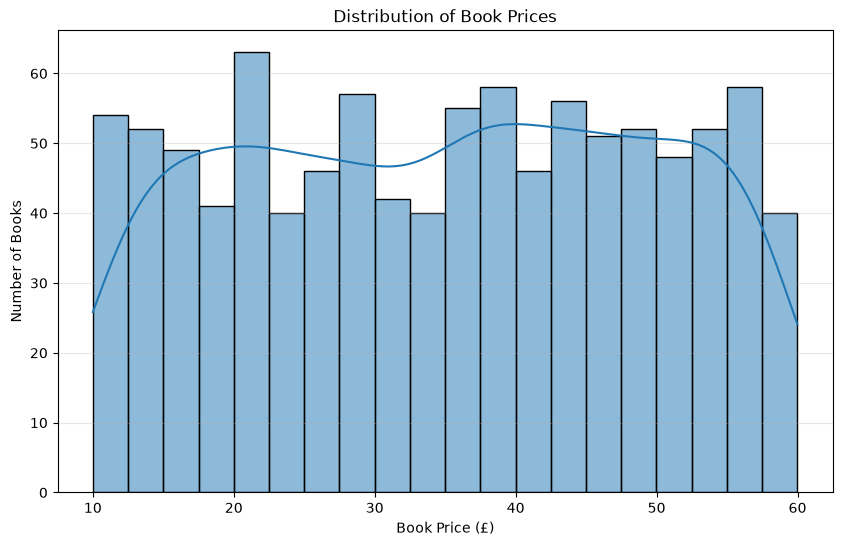

In [14]:
# Visualise the distribution of book prices

plt.figure(figsize=(10, 6))

sns.histplot(
    data=cleaned_df,
    x="Price_GBP",
    bins=20,
    kde=True
)

plt.title("Distribution of Book Prices")
plt.xlabel("Book Price (£)")
plt.ylabel("Number of Books")
plt.grid(axis="y", alpha=0.3)

plt.show()

**Interpretation:**

The histogram shows the distribution of book prices across the 1,000 books collected. Prices range approximately from £10 to £60. The distribution is relatively spread out, with books appearing across most price intervals. There is no single price range that overwhelmingly dominates the catalogue. This suggests that the website offers books at a wide range of prices.

### 5.2 Average Book Prices by Category

A bar chart is used to compare the average prices of the ten most expensive book categories. This visualisation helps identify categories with higher average prices and highlights differences in pricing across genres.

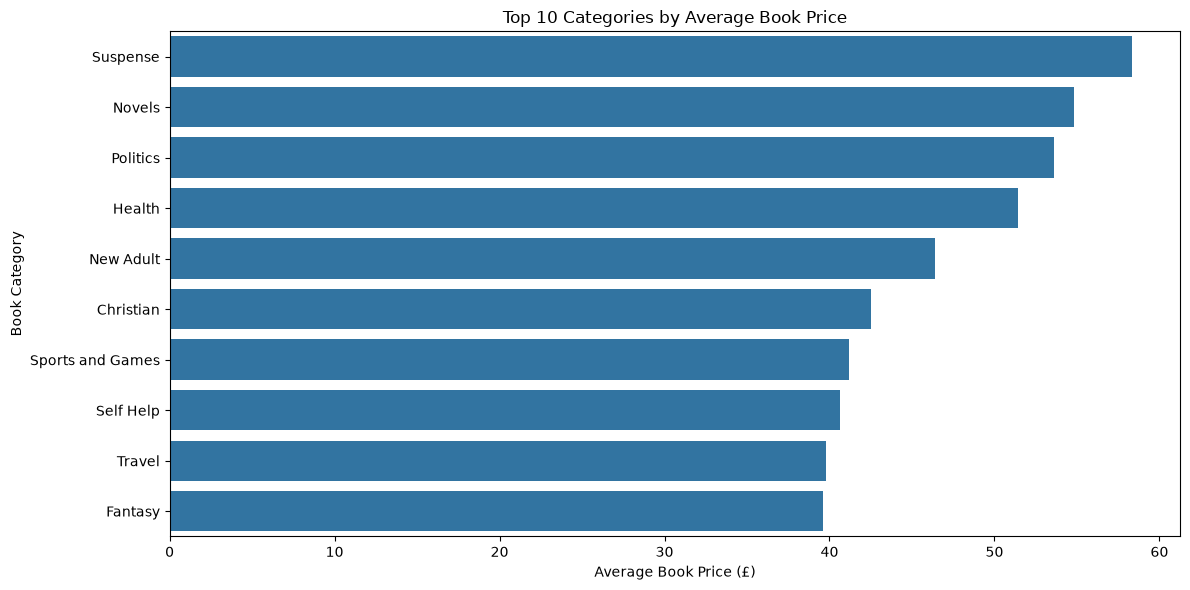

In [15]:
# Select the 10 most expensive categories
top_10_categories = category_prices.head(10)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index
)

plt.title("Top 10 Categories by Average Book Price")
plt.xlabel("Average Book Price (£)")
plt.ylabel("Book Category")
plt.tight_layout()

plt.show()

### 5.3 Analysis of Book Ratings

This section examines the distribution of book ratings and investigates the relationship between customer ratings and book prices. The analysis helps determine whether books with higher ratings tend to have higher average prices.

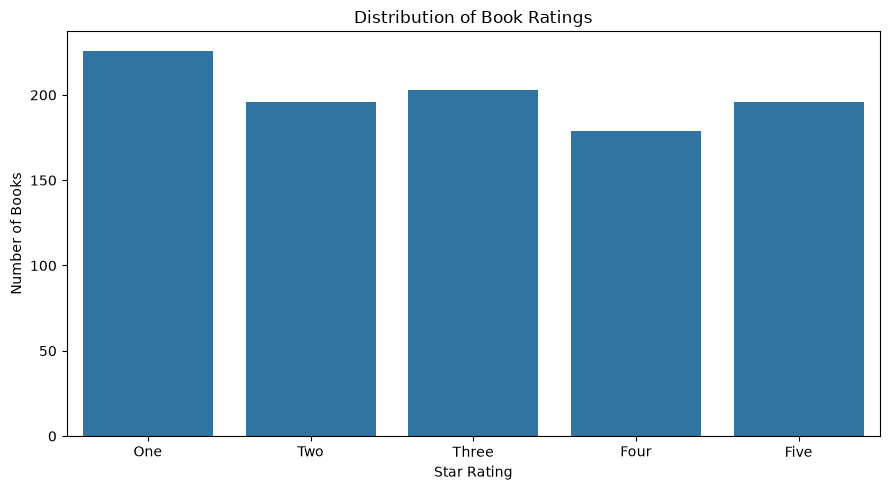

In [16]:
# Count books in each rating category
rating_counts = cleaned_df["Rating"].value_counts()

# Arrange ratings in the correct order
rating_order = ["One", "Two", "Three", "Four", "Five"]

rating_counts = rating_counts.reindex(rating_order)

# Create bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.tight_layout()

plt.show()

In [18]:
# Calculate average price for each rating
rating_prices = (
    cleaned_df.groupby("Rating")["Price_GBP"]
    .mean()
    .reindex(rating_order)
)

print("AVERAGE BOOK PRICE BY RATING")
display(rating_prices.round(2))


AVERAGE BOOK PRICE BY RATING


Rating
One      34.56
Two      34.81
Three    34.69
Four     36.09
Five     35.37
Name: Price_GBP, dtype: float64

**Interpretation of Book Ratings and Prices**

The analysis shows that books with different star ratings have relatively similar average prices. Four-star books have the highest average price of £36.09, followed by five-star books at £35.37. One-star books have the lowest average price at £34.56.

These results suggest that higher customer ratings do not necessarily correspond to substantially higher book prices. Therefore, other factors, such as book category and publishing characteristics, may also influence pricing.

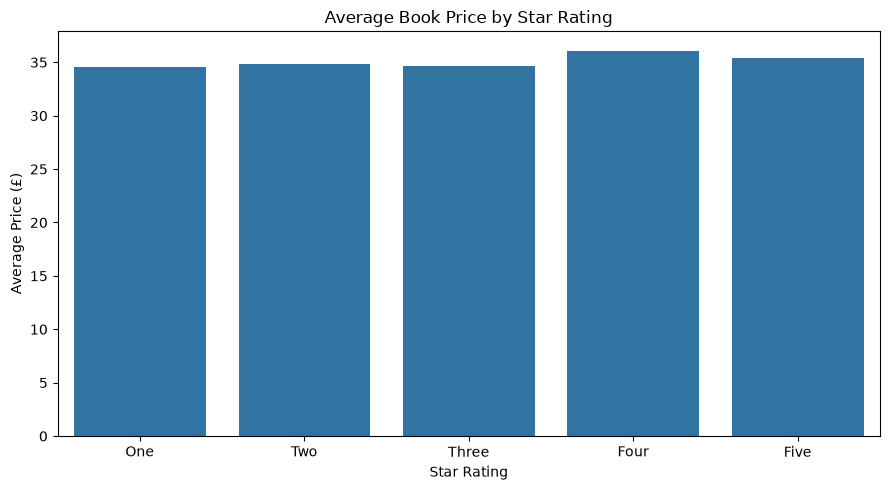

In [19]:
# Create a bar chart of average prices by rating

plt.figure(figsize=(9, 5))

sns.barplot(
    x=rating_prices.index,
    y=rating_prices.values
)

plt.title("Average Book Price by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Price (£)")
plt.tight_layout()

plt.show()

## 6. Predictive Modelling

### 6.1 Linear Regression Model

Linear Regression is a supervised machine learning technique used to predict continuous numerical values. In this project, it is used to predict book prices based on information such as book category, star rating and stock quantity.

The dataset is divided into training and testing sets. The training data is used to develop the model, while the testing data evaluates its ability to predict prices for previously unseen books.

In [20]:
# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Select features for predicting book prices
X = cleaned_df[["Category", "Rating", "Quantity"]]

# Target variable
y = cleaned_df["Price_GBP"]

# Divide the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("DATA PREPARATION COMPLETED")
print("---------------------------")
print("Total records:", len(cleaned_df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Input features:", list(X.columns))

DATA PREPARATION COMPLETED
---------------------------
Total records: 1000
Training records: 800
Testing records: 200
Input features: ['Category', 'Rating', 'Quantity']


### 6.2 Training the Linear Regression Model

A Linear Regression model is trained using the selected input features: book category, star rating and stock quantity. Categorical variables are converted into numerical representations using One-Hot Encoding so that they can be processed by the machine learning algorithm.

In [21]:
# Identify categorical and numerical features
categorical_features = ["Category", "Rating"]
numerical_features = ["Quantity"]

# Prepare the data transformation
preprocessor = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numbers", "passthrough", numerical_features)
    ]
)

# Create the Linear Regression pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("LINEAR REGRESSION MODEL TRAINED SUCCESSFULLY!")
print("Training records:", len(X_train))
print("Input features:", list(X.columns))

LINEAR REGRESSION MODEL TRAINED SUCCESSFULLY!
Training records: 800
Input features: ['Category', 'Rating', 'Quantity']


In [22]:
# Predict prices using the testing dataset
y_pred = model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price (£)": y_test.values,
    "Predicted Price (£)": y_pred
})

print("ACTUAL VS PREDICTED BOOK PRICES")
display(comparison.head(10).round(2))

ACTUAL VS PREDICTED BOOK PRICES


,Actual Price (£),Predicted Price (£)
0,40.72,33.69
1,58.75,40.36
2,55.85,47.33
3,56.59,38.42
4,41.67,35.48
5,50.11,36.96
6,14.07,37.41
7,58.87,35.45
8,11.83,30.68
9,21.71,36.58


### 6.3 Model Evaluation

The performance of the Linear Regression model is evaluated using three statistical metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and the R-squared (R²) score. These metrics measure the prediction errors and explain how well the model accounts for variations in book prices.

In [23]:
# Calculate model evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION MODEL PERFORMANCE")
print("===================================")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R2):", round(r2, 4))

LINEAR REGRESSION MODEL PERFORMANCE
Mean Absolute Error (MAE): 12.49
Root Mean Squared Error (RMSE): 14.87
R-squared (R2): -0.0733


### 6.4 Actual Versus Predicted Book Prices

A scatter plot is used to compare the actual book prices with the prices predicted by the Linear Regression model. The visualisation helps identify how closely the predictions follow the actual values and highlights prediction errors.

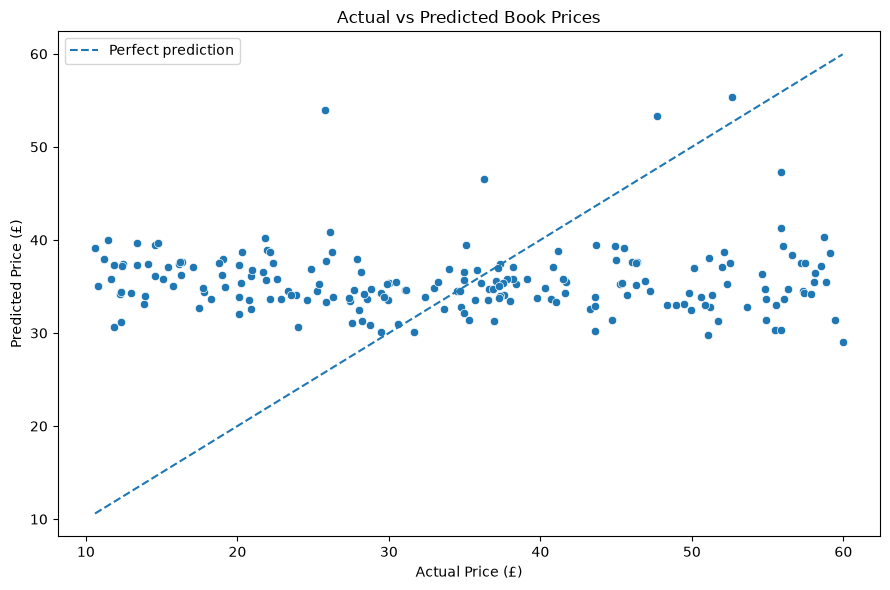

In [24]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred
)

# Reference line for perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect prediction"
)

plt.title("Actual vs Predicted Book Prices")
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.legend()
plt.tight_layout()

plt.show()

In [25]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION MODEL PERFORMANCE")
print("===================================")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R2):", round(r2, 4))

LINEAR REGRESSION MODEL PERFORMANCE
Mean Absolute Error (MAE): 12.49
Root Mean Squared Error (RMSE): 14.87
R-squared (R2): -0.0733


### 6.5 Interpretation of Model Performance

The Linear Regression model achieved a Mean Absolute Error (MAE) of £12.49, meaning that its predictions differed from the actual book prices by approximately £12.49 on average. The Root Mean Squared Error (RMSE) was £14.87, indicating that some predictions had relatively large errors.

The model achieved an R-squared value of -0.0733. This negative value indicates that the model performed worse than a baseline approach that predicts the average book price for every book.

These results suggest that the selected features, namely book category, star rating and stock quantity, were not sufficient to predict book prices accurately. Additional features and alternative modelling approaches could be explored to improve prediction performance.

## 7. Conclusion

This project analysed book market data collected from the Books to Scrape website. Using Python, Requests and BeautifulSoup, a dataset containing 1,000 books across 50 categories was successfully collected.

The dataset included book titles, prices, ratings, availability, stock quantities and categories. Data cleaning was performed to ensure that the dataset was consistent and ready for analysis.

Exploratory Data Analysis was used to investigate book price distributions, category averages and rating patterns. The findings showed that average book prices varied across categories, while prices across different star ratings were relatively similar.

A Linear Regression model was developed using book category, rating and stock quantity to predict prices. The model achieved an MAE of £12.49, an RMSE of £14.87 and an R-squared value of -0.0733. These results indicate that the selected features were not sufficient to predict book prices accurately.

Overall, the project demonstrated how web scraping, data cleaning, visualisation and machine learning can be combined to analyse an online book catalogue. It also highlighted the importance of selecting relevant features when developing predictive models.

## 8. Recommendations

Based on the analysis, the following recommendations are proposed:

1. **Improve price prediction:** Include additional book information, such as book descriptions, length, publication details and other relevant features, where available.
2. **Explore other models:** Test alternative regression algorithms and compare their performance with Linear Regression.
3. **Monitor category prices:** Online retailers can use category-level price analysis to understand differences in catalogue pricing.
4. **Use data-driven decisions:** Bookstores can use catalogue analysis to support pricing, stock management and product selection.
5. **Improve future analysis:** Collect additional data over time to identify changes in book prices and catalogue trends.